# 00 — Point Robot and Expert Demonstrations

We start with the simplest possible continuous-control problem.

A point robot moves in a 2D workspace from a start position to a goal while
avoiding an obstacle.

The environment is deliberately simple: the objective is not to study physics,
but to isolate the learning problem that will later appear in robotic
manipulation.

We will use this environment to introduce:

- state, observation, and action
- dynamics
- policy
- trajectory and episode
- expert demonstrations
- multimodal behavior

## State, observation, and action

At time $t$, the robot position is

$$
p_t = [x_t, y_t].
$$

The complete environment state also contains the goal and obstacle:

$$
s_t = (p_t, p_g, \mathcal O).
$$

A policy does not necessarily observe the complete state. We denote its
observation by

$$
o_t.
$$

For our first experiments, the observation will contain the robot and goal
positions:

$$
o_t = [x_t, y_t, x_g, y_g].
$$

The action is a desired 2D displacement:

$$
a_t = [\Delta x_t, \Delta y_t].
$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

START = np.array([0.0, 0.0])
GOAL = np.array([0.0, 1.0])

MAX_ACTION = 0.05

In [ ]:
# Simulate a step in the environment
def step(position, action):
    norm = np.linalg.norm(action)

    if norm > MAX_ACTION:
        action = action / norm * MAX_ACTION

    return position + action

In [4]:
# Define an expert policy for the point robot, which moves directly towards the goal (scripted policy)
def expert_policy(position, goal):
    direction = goal - position
    distance = np.linalg.norm(direction)

    if distance < 1e-8:
        return np.zeros(2)

    return direction / distance * min(distance, MAX_ACTION)

In [8]:
def make_observation(position, goal):
    return np.concatenate([position, goal])


def rollout(policy, start, goal, max_steps=100):
    position = start.copy()

    observations = []
    actions = []
    positions = [position.copy()]

    for _ in range(max_steps):
        observation = make_observation(position, goal)
        action = policy(position, goal)

        observations.append(observation)
        actions.append(action)

        position = step(position, action)
        positions.append(position.copy())

        if np.linalg.norm(position - goal) < 1e-3:
            break

    return {
        "observations": np.array(observations),
        "actions": np.array(actions),
        "positions": np.array(positions),
    }

observations: (20, 4)
actions:      (20, 2)
positions:    (21, 2)


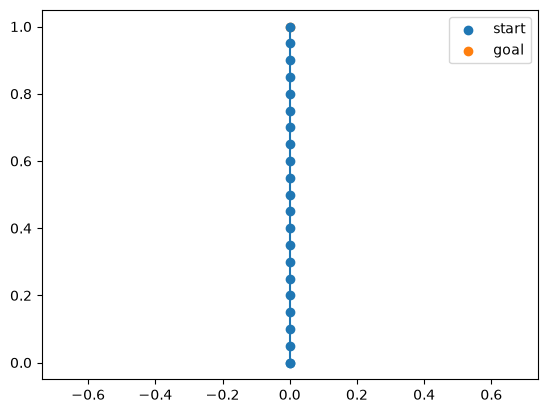

In [10]:
trajectory = rollout(expert_policy, START, GOAL)

print("observations:", trajectory["observations"].shape)
print("actions:     ", trajectory["actions"].shape)
print("positions:   ", trajectory["positions"].shape)

plt.plot(trajectory["positions"][:, 0], trajectory["positions"][:, 1], "-o")
plt.scatter(*START, label="start")
plt.scatter(*GOAL, label="goal")

plt.axis("equal")
plt.legend()
plt.show()